In [1]:
import sys
from pathlib import Path
  
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
import warnings
import cv2
import random

%load_ext autoreload
%autoreload 2

pd.set_option('display.max_columns', None)
pd.set_option('display.expand_frame_repr', False)
warnings.filterwarnings('ignore')
np.set_printoptions(suppress=True, precision=3)

In [2]:
# Add project root directory to Python path to allow importing from src folder
notebook_dir = Path("__file__").resolve().parent
project_root = Path.cwd().parent
sys.path.append(str(project_root))

In [5]:
# import utils

from src.utils_classical import feature_reduction, split_data, generate_objective
from src.utils_plotting import plot_tsne, plot_umap, create_classification_report

In [6]:
# Read dataset
from src.utils_data import FEATURE_DATA_FOLDER, PLANT_CLASS_DICT

feature_dataset_path: Path = FEATURE_DATA_FOLDER / "feature_dataset.csv"
df = pd.read_csv(feature_dataset_path)
df.head()

,image_filename,class_name,class_number,rgb_0_mean,rgb_0_std,rgb_0_skewness,rgb_1_mean,rgb_1_std,rgb_1_skewness,rgb_2_mean,rgb_2_std,rgb_2_skewness,hsv_0_mean,hsv_0_std,hsv_0_skewness,hsv_1_mean,hsv_1_std,hsv_1_skewness,hsv_2_mean,hsv_2_std,hsv_2_skewness,lab_0_mean,lab_0_std,lab_0_skewness,lab_1_mean,lab_1_std,lab_1_skewness,lab_2_mean,lab_2_std,lab_2_skewness,rgb_0_hist_0,rgb_0_hist_1,rgb_0_hist_2,rgb_0_hist_3,rgb_0_hist_4,rgb_0_hist_5,rgb_0_hist_6,rgb_0_hist_7,rgb_0_hist_8,rgb_0_hist_9,rgb_0_hist_10,rgb_0_hist_11,rgb_0_hist_12,rgb_0_hist_13,rgb_0_hist_14,rgb_0_hist_15,rgb_0_hist_16,rgb_0_hist_17,rgb_0_hist_18,rgb_0_hist_19,rgb_0_hist_20,rgb_0_hist_21,rgb_0_hist_22,rgb_0_hist_23,rgb_0_hist_24,rgb_0_hist_25,rgb_0_hist_26,rgb_0_hist_27,rgb_0_hist_28,rgb_0_hist_29,rgb_0_hist_30,rgb_0_hist_31,rgb_1_hist_0,rgb_1_hist_1,rgb_1_hist_2,rgb_1_hist_3,rgb_1_hist_4,rgb_1_hist_5,rgb_1_hist_6,rgb_1_hist_7,rgb_1_hist_8,rgb_1_hist_9,rgb_1_hist_10,rgb_1_hist_11,rgb_1_hist_12,rgb_1_hist_13,rgb_1_hist_14,rgb_1_hist_15,rgb_1_hist_16,rgb_1_hist_17,rgb_1_hist_18,rgb_1_hist_19,rgb_1_hist_20,rgb_1_hist_21,rgb_1_hist_22,rgb_1_hist_23,rgb_1_hist_24,rgb_1_hist_25,rgb_1_hist_26,rgb_1_hist_27,rgb_1_hist_28,rgb_1_hist_29,rgb_1_hist_30,rgb_1_hist_31,rgb_2_hist_0,rgb_2_hist_1,rgb_2_hist_2,rgb_2_hist_3,rgb_2_hist_4,rgb_2_hist_5,rgb_2_hist_6,rgb_2_hist_7,rgb_2_hist_8,rgb_2_hist_9,rgb_2_hist_10,rgb_2_hist_11,rgb_2_hist_12,rgb_2_hist_13,rgb_2_hist_14,rgb_2_hist_15,rgb_2_hist_16,rgb_2_hist_17,rgb_2_hist_18,rgb_2_hist_19,rgb_2_hist_20,rgb_2_hist_21,rgb_2_hist_22,rgb_2_hist_23,rgb_2_hist_24,rgb_2_hist_25,rgb_2_hist_26,rgb_2_hist_27,rgb_2_hist_28,rgb_2_hist_29,rgb_2_hist_30,rgb_2_hist_31,hsv_0_hist_0,hsv_0_hist_1,hsv_0_hist_2,hsv_0_hist_3,hsv_0_hist_4,hsv_0_hist_5,hsv_0_hist_6,hsv_0_hist_7,hsv_0_hist_8,hsv_0_hist_9,hsv_0_hist_10,hsv_0_hist_11,hsv_0_hist_12,hsv_0_hist_13,hsv_0_hist_14,hsv_0_hist_15,hsv_0_hist_16,hsv_0_hist_17,hsv_0_hist_18,hsv_0_hist_19,hsv_0_hist_20,hsv_0_hist_21,hsv_0_hist_22,hsv_0_hist_23,hsv_0_hist_24,hsv_0_hist_25,hsv_0_hist_26,hsv_0_hist_27,hsv_0_hist_28,hsv_0_hist_29,hsv_0_hist_30,hsv_0_hist_31,hsv_1_hist_0,hsv_1_hist_1,hsv_1_hist_2,hsv_1_hist_3,hsv_1_hist_4,hsv_1_hist_5,hsv_1_hist_6,hsv_1_hist_7,hsv_1_hist_8,hsv_1_hist_9,hsv_1_hist_10,hsv_1_hist_11,hsv_1_hist_12,hsv_1_hist_13,hsv_1_hist_14,hsv_1_hist_15,hsv_1_hist_16,hsv_1_hist_17,hsv_1_hist_18,hsv_1_hist_19,hsv_1_hist_20,hsv_1_hist_21,hsv_1_hist_22,hsv_1_hist_23,hsv_1_hist_24,hsv_1_hist_25,hsv_1_hist_26,hsv_1_hist_27,hsv_1_hist_28,hsv_1_hist_29,hsv_1_hist_30,hsv_1_hist_31,hsv_2_hist_0,hsv_2_hist_1,hsv_2_hist_2,hsv_2_hist_3,hsv_2_hist_4,hsv_2_hist_5,hsv_2_hist_6,hsv_2_hist_7,hsv_2_hist_8,hsv_2_hist_9,hsv_2_hist_10,hsv_2_hist_11,hsv_2_hist_12,hsv_2_hist_13,hsv_2_hist_14,hsv_2_hist_15,hsv_2_hist_16,hsv_2_hist_17,hsv_2_hist_18,hsv_2_hist_19,hsv_2_hist_20,hsv_2_hist_21,hsv_2_hist_22,hsv_2_hist_23,hsv_2_hist_24,hsv_2_hist_25,hsv_2_hist_26,hsv_2_hist_27,hsv_2_hist_28,hsv_2_hist_29,hsv_2_hist_30,hsv_2_hist_31,lab_0_hist_0,lab_0_hist_1,lab_0_hist_2,lab_0_hist_3,lab_0_hist_4,lab_0_hist_5,lab_0_hist_6,lab_0_hist_7,lab_0_hist_8,lab_0_hist_9,lab_0_hist_10,lab_0_hist_11,lab_0_hist_12,lab_0_hist_13,lab_0_hist_14,lab_0_hist_15,lab_0_hist_16,lab_0_hist_17,lab_0_hist_18,lab_0_hist_19,lab_0_hist_20,lab_0_hist_21,lab_0_hist_22,lab_0_hist_23,lab_0_hist_24,lab_0_hist_25,lab_0_hist_26,lab_0_hist_27,lab_0_hist_28,lab_0_hist_29,lab_0_hist_30,lab_0_hist_31,lab_1_hist_0,lab_1_hist_1,lab_1_hist_2,lab_1_hist_3,lab_1_hist_4,lab_1_hist_5,lab_1_hist_6,lab_1_hist_7,lab_1_hist_8,lab_1_hist_9,lab_1_hist_10,lab_1_hist_11,lab_1_hist_12,lab_1_hist_13,lab_1_hist_14,lab_1_hist_15,lab_1_hist_16,lab_1_hist_17,lab_1_hist_18,lab_1_hist_19,lab_1_hist_20,lab_1_hist_21,lab_1_hist_22,lab_1_hist_23,lab_1_hist_24,lab_1_hist_25,lab_1_hist_26,lab_1_hist_27,lab_1_hist_28,lab_1_hist_29,lab_1_hist_30,lab_1_hist_31,lab_2_hist_0,lab_2_hist_1,lab_2_hist_2,lab_2_hist_3,lab_2_hist_4,lab_2_hist_5,lab_2_hist_6,lab_2_hist_7,lab_2_hist_8,lab_2_hist_9,la

In [7]:
X = df.drop(columns=['class_name', 'class_number', 'image_filename'])
y = df['class_number']

print(X.info())
print(y.info())
target_names = list(PLANT_CLASS_DICT.values())

<class 'pandas.DataFrame'>
RangeIndex: 4971 entries, 0 to 4970
Columns: 371 entries, rgb_0_mean to vesselness_std
dtypes: float64(371)
memory usage: 14.1 MB
None
<class 'pandas.Series'>
RangeIndex: 4971 entries, 0 to 4970
Series name: class_number
Non-Null Count  Dtype
--------------  -----
4971 non-null   int64
dtypes: int64(1)
memory usage: 39.0 KB
None


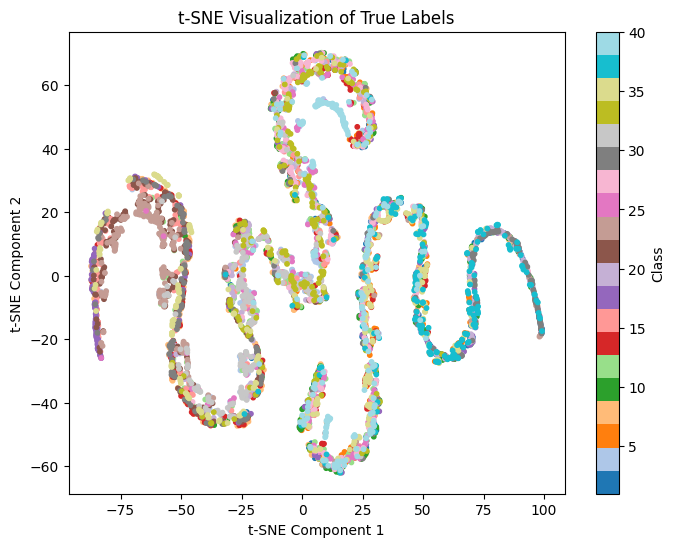

In [ ]:
# Plot of T-SNE to show how features differentiate to each classes
plot_tsne(X, y)

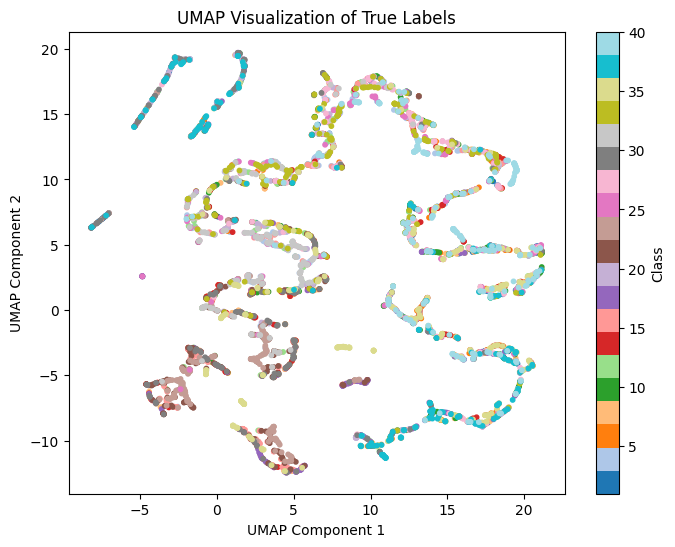

In [35]:
# Plot of UMAP to show how features differentiate to each classes
plot_umap(X, y)

In [8]:
X_train, X_test, y_train, y_test = split_data(X, y)

In [9]:
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.svm import SVC
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import GridSearchCV

pipe = Pipeline([
    ("scaler", StandardScaler()),
    ("select", SelectKBest(score_func=f_classif)),
    ("svm", SVC(kernel="rbf"))
])

params = {
    "select__k": [10, 25, 50, 75, 100, 150, 200, 250, 300, 350, 371],
    "svm__C": [0.1, 1, 10, 100],
    "svm__gamma": ["scale", 0.01, 0.001]
}

grid = GridSearchCV(
    pipe,
    params,
    cv=5,
    scoring="accuracy",
    n_jobs=-1
)

grid.fit(X_train, y_train)

print("Best Parameters:")
print(grid.best_params_)

print("\nBest CV Accuracy:")
print(grid.best_score_)

print("\nTest Accuracy:")
print(grid.score(X_test, y_test))

Best Parameters:
{'select__k': 200, 'svm__C': 100, 'svm__gamma': 0.001}

Best CV Accuracy:
0.9738439593153064

Test Accuracy:
0.9805630026809652


In [16]:
best_k = grid.best_params_["select__k"]
best_model = grid.best_estimator_

print("Best k:", best_k)

selector = best_model.named_steps["select"]
selected_indices = selector.get_support(indices=True)

print(selected_indices)

feature_names = X.columns
selected_features = feature_names[selected_indices]
print(selected_features)

Best k: 200
[  0   1   2   3   4   5   6   7   8   9  10  11  12  13  14  15  16  17
  18  19  20  21  22  23  24  25  26  29  30  31  32  33  34  35  36  37
  38  42  43  45  46  47  48  49  50  51  53  54  58  66  67  70  71  72
  73  74  79  80  81  82  83  85  86  90  99 100 101 102 103 105 106 111
 112 113 114 115 117 118 119 122 123 126 127 128 129 131 132 133 135 136
 138 144 145 155 156 158 161 171 172 173 174 175 176 177 178 179 180 181
 198 199 200 201 202 203 204 205 206 207 208 209 210 211 213 214 215 218
 229 230 231 232 233 234 238 239 240 241 242 243 244 246 247 250 262 263
 264 265 266 267 268 298 299 315 317 320 321 322 323 324 325 326 328 329
 330 331 332 333 334 335 336 337 338 339 340 341 342 343 344 345 346 347
 348 349 350 351 352 353 354 355 356 357 358 359 360 361 362 363 366 367
 368 369]
Index(['rgb_0_mean', 'rgb_0_std', 'rgb_0_skewness', 'rgb_1_mean', 'rgb_1_std',
       'rgb_1_skewness', 'rgb_2_mean', 'rgb_2_std', 'rgb_2_skewness',
       'hsv_0_mean',
     

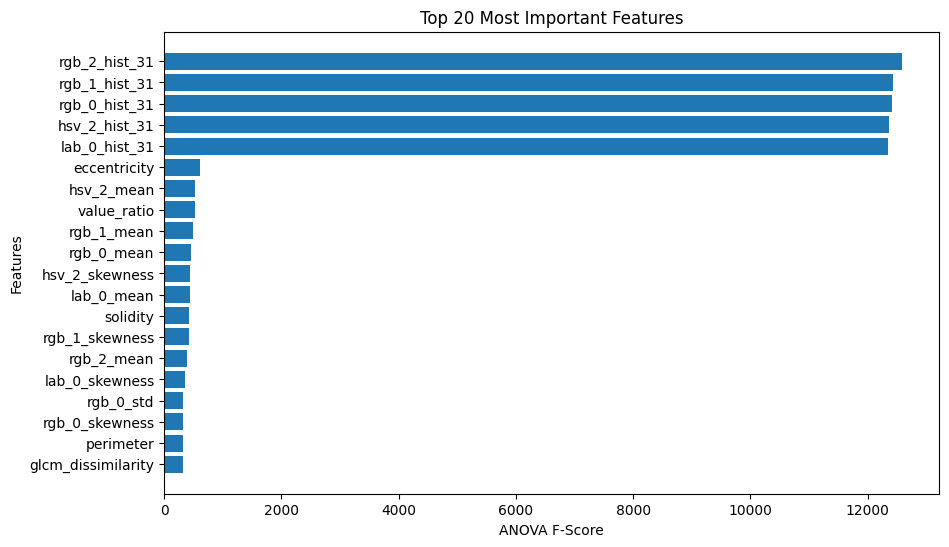

In [22]:
# Get ANOVA F-scores
scores = selector.scores_

feature_importance = pd.DataFrame({
    "Feature": feature_names,
    "F_Score": scores
})

# Sort descending
feature_importance = feature_importance.sort_values(
    by="F_Score",
    ascending=False
)

# Show top 20
top_features = feature_importance.head(20)

# Plot
plt.figure(figsize=(10, 6))
plt.barh(
    top_features["Feature"],
    top_features["F_Score"]
)

plt.xlabel("ANOVA F-Score")
plt.ylabel("Features")
plt.title("Top 20 Most Important Features")
plt.gca().invert_yaxis()

plt.show()

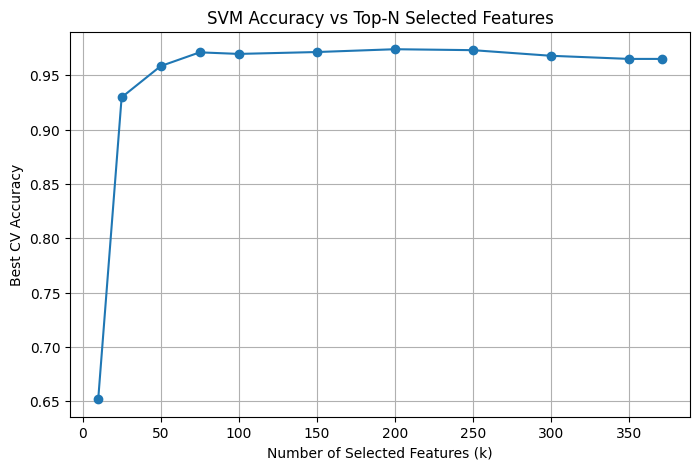

In [18]:
results = pd.DataFrame(grid.cv_results_)

k_scores = results.groupby("param_select__k")["mean_test_score"].max()

plt.figure(figsize=(8, 5))
plt.plot(k_scores.index, k_scores.values, marker="o")
plt.xlabel("Number of Selected Features (k)")
plt.ylabel("Best CV Accuracy")
plt.title("SVM Accuracy vs Top-N Selected Features")
plt.grid(True)
plt.show()

In [19]:
k_scores

param_select__k
10     0.651906
25     0.929580
50     0.958317
75     0.970966
100    0.969531
150    0.971256
200    0.973844
250    0.972979
300    0.967805
350    0.964931
371    0.964931
Name: mean_test_score, dtype: float64

In [ ]:
# Get best fitted pipeline
best_model = grid.best_estimator_

# Transform using scaler + selected Top-K features
X_train_scaled = best_model.named_steps["scaler"].transform(X_train)
X_train_topk = best_model.named_steps["select"].transform(X_train_scaled)

print(X_train_topk.shape)

(3479, 200)


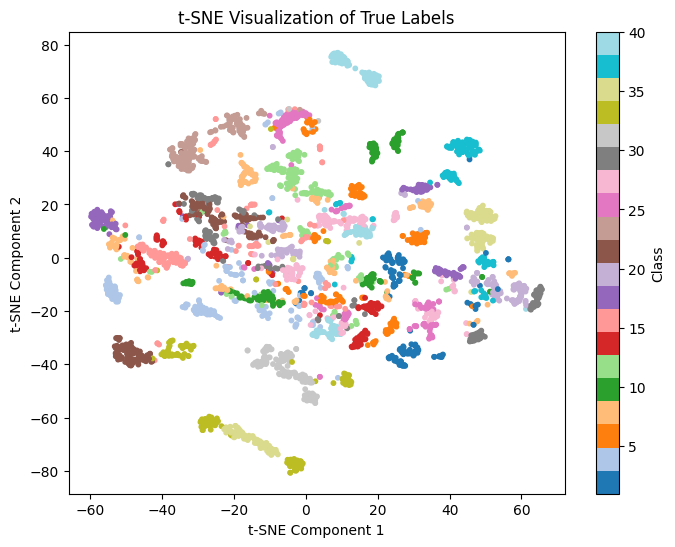

In [12]:
# Plot of T-SNE to show how features differentiate to each classes
plot_tsne(X_train_topk, y_train)

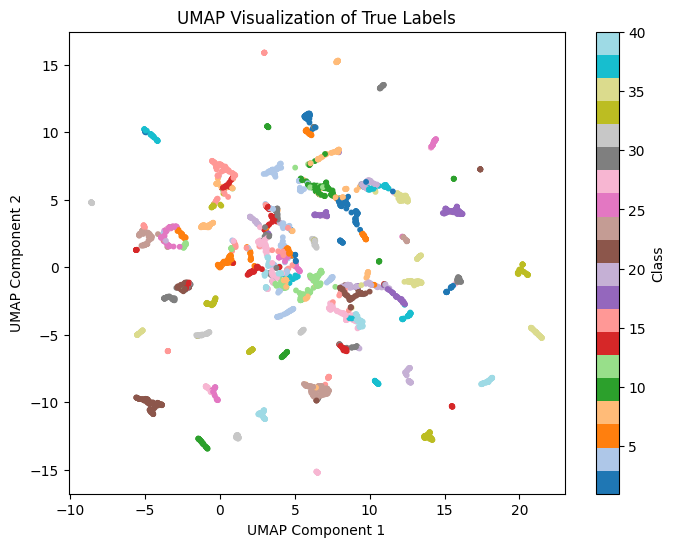

In [13]:
# Plot of UMAP to show how features differentiate to each classes
plot_umap(X_train_topk, y_train)